TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Extracting /content/pets/images.tar.gz ...
Extracting /content/pets/annotations.tar.gz ...
Raw train files: 3680
Raw test files: 3669
Verifying image files (lightweight check, not loading pixels)...
Train files: 3680
Test files: 3669

--- Config 1/5: {'weight_init': 'he_normal', 'optimizer': 'adam', 'lr': 0.001, 'dropout_rate': 0.4, 'l2_reg': 0.0001} ---
Epoch 1/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 30s 188ms/step - accuracy: 0.0575 - loss: 3.9794 - val_accuracy: 0.0036 - val_loss: 4.0792
Epoch 2/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - accuracy: 0.0793 - loss: 3.7449 - val_accuracy: 0.0054 - val_loss: 4.2236
Epoch 3/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 10s 97ms/step - accuracy: 0.0882 - loss: 3.6072 - val_accuracy: 0.0072 - val_loss: 4.2887
Epoch 4/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - accuracy: 0.1058 - loss: 3.5071 - val_accuracy: 0.0399 - val_loss: 3.8556
Epoch 5/5
98/98 ━━━━━━━

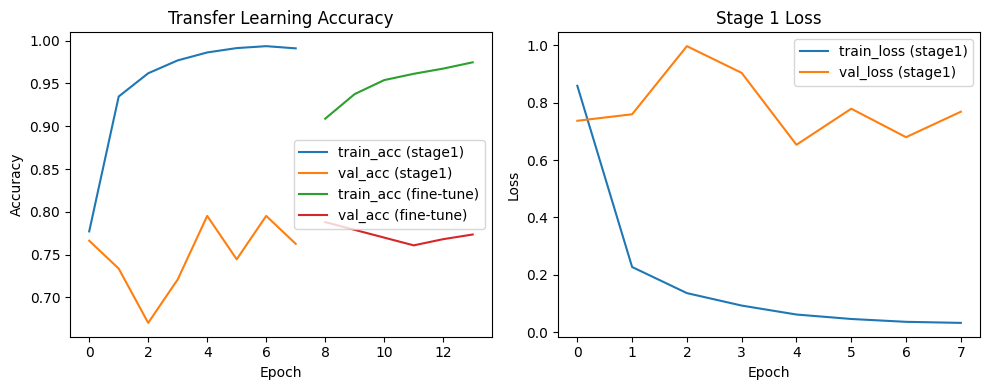

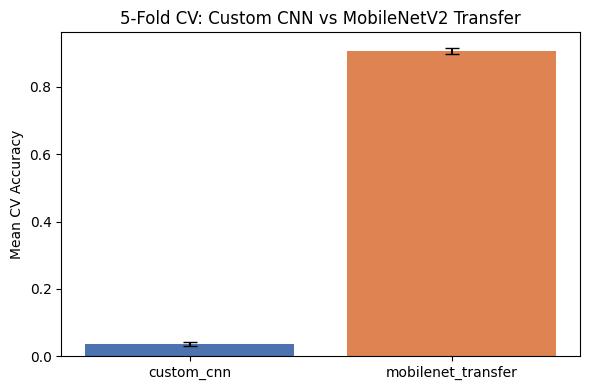

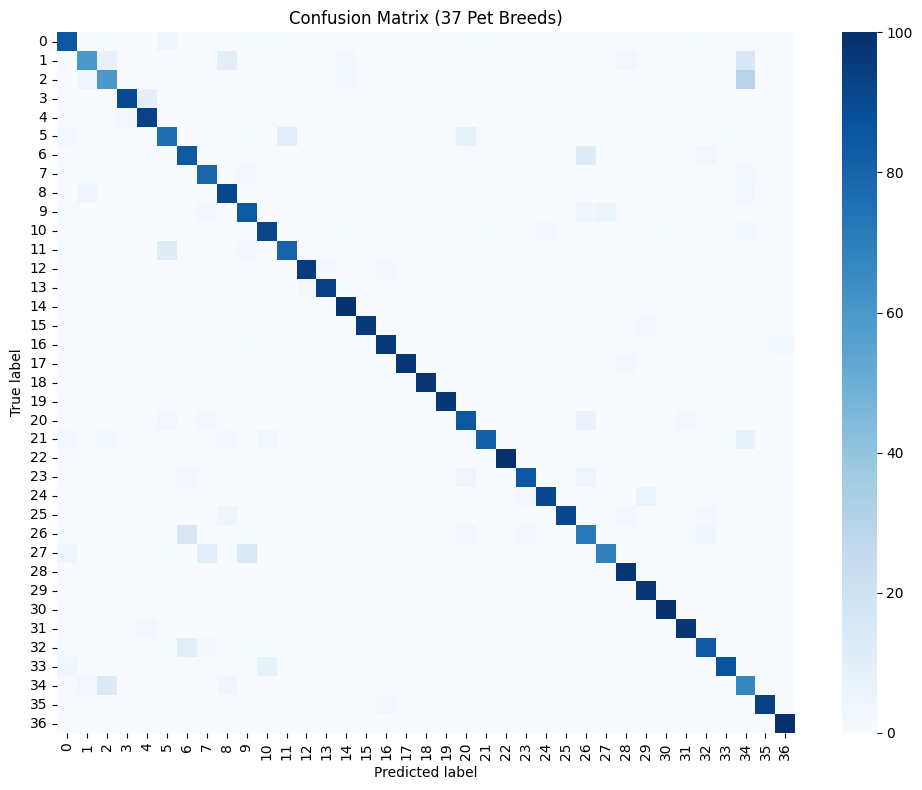

Model saved as final_pet_classifier.keras


In [ ]:
# =============================================================================
# Experiment: CNN Training & Optimization on Oxford-IIIT Pet Dataset
# Topics covered: Weight Initialization, Regularization (L2), Batch Normalization,
# Dropout, Optimizers, CNN Hyperparameters, Transfer Learning & Fine-Tuning
# (MobileNetV2), and 5-Fold Cross-Validation for model selection.
#
# HOW TO USE IN GOOGLE COLAB:
# 1. Create a new Colab notebook.
# 2. Set Runtime > Change runtime type > GPU (T4 recommended).
# 3. Copy each "# %% CELL n" block below into a separate Colab cell
#    (or just paste the whole file into one cell and run it top to bottom).
# =============================================================================

# %% CELL 1: Install / Imports
# NOTE: tensorflow_datasets is intentionally NOT used -- in current Colab
# images it pulls in a tensorflow_metadata build that needs a newer protobuf
# runtime than the one preinstalled, which throws:
#   "AttributeError: module 'tensorflow_datasets' has no attribute 'load'"
# We instead download the Oxford-IIIT Pet dataset directly from its source,
# which avoids that conflict entirely.
!pip install -q tensorflow scikit-learn matplotlib seaborn pillow

import os
import tarfile
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image
from tensorflow.keras import layers, models, regularizers, optimizers, initializers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.model_selection import KFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)

tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

IMG_SIZE = 224
CHANNELS = 3
BATCH_SIZE = 32
NUM_CLASSES = 37   # Oxford-IIIT Pet has 37 breeds

# %% CELL 2: Download & Load Oxford-IIIT Pet Dataset (direct source, no tfds)
DATA_DIR = '/content/pets'
os.makedirs(DATA_DIR, exist_ok=True)

IMAGES_URL = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz"
ANNOTATIONS_URL = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz"

for url in [IMAGES_URL, ANNOTATIONS_URL]:
    fname = os.path.join(DATA_DIR, os.path.basename(url))
    if not os.path.exists(fname):
        print(f"Downloading {url} ...")
        urllib.request.urlretrieve(url, fname)
    extracted_marker = fname + '.extracted'
    if not os.path.exists(extracted_marker):
        print(f"Extracting {fname} ...")
        with tarfile.open(fname) as tar:
            try:
                tar.extractall(DATA_DIR, filter='data')
            except TypeError:
                # Older Python versions don't support the `filter` kwarg
                tar.extractall(DATA_DIR)
        open(extracted_marker, 'w').close()

IMAGES_DIR = os.path.join(DATA_DIR, 'images')
ANNOT_DIR = os.path.join(DATA_DIR, 'annotations')


def parse_list_file(list_path):
    """
    Parses annotations/trainval.txt or annotations/test.txt.
    Each non-comment line has the form:
        <image_name> <class_id (1-37)> <species_id> <breed_id>
    Returns parallel lists of image file paths and zero-indexed class labels.
    """
    filepaths, labels = [], []
    with open(list_path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split()
            name, class_id = parts[0], int(parts[1]) - 1  # zero-index 0..36
            filepaths.append(os.path.join(IMAGES_DIR, name + '.jpg'))
            labels.append(class_id)
    return filepaths, labels


train_files, train_labels_raw = parse_list_file(os.path.join(ANNOT_DIR, 'trainval.txt'))
test_files, test_labels_raw = parse_list_file(os.path.join(ANNOT_DIR, 'test.txt'))

print("Raw train files:", len(train_files))
print("Raw test files:", len(test_files))


def filter_valid_files(filepaths, labels):
    """
    Lightweight pass that just verifies each image can be opened (a few
    files in this dataset are truncated/corrupted). This only reads file
    headers via PIL's verify(), so it is cheap on RAM -- unlike loading
    every image into a big numpy array up front, which is what previously
    caused Colab to run out of RAM and crash the session.
    """
    valid_fp, valid_lbl = [], []
    for fp, lbl in zip(filepaths, labels):
        try:
            with Image.open(fp) as img:
                img.verify()
            valid_fp.append(fp)
            valid_lbl.append(lbl)
        except Exception as e:
            print(f"Skipping corrupt file {fp}: {e}")
    return valid_fp, valid_lbl


print("Verifying image files (lightweight check, not loading pixels)...")
train_files, train_labels_raw = filter_valid_files(train_files, train_labels_raw)
test_files, test_labels_raw = filter_valid_files(test_files, test_labels_raw)

# Keep only file paths + integer labels in memory (a few hundred KB total).
# Actual pixel data is decoded lazily, batch-by-batch, inside the tf.data
# pipeline built in Cell 3 -- this is what keeps RAM usage bounded.
train_files_arr = np.array(train_files)
train_labels_arr = np.array(train_labels_raw, dtype=np.int64)
test_files_arr = np.array(test_files)
test_labels_arr = np.array(test_labels_raw, dtype=np.int64)

print("Train files:", len(train_files_arr))
print("Test files:", len(test_files_arr))

# %% CELL 3: Build tf.data pipelines (lazy loading from disk, not from RAM arrays)
import gc


def load_and_preprocess(filepath, label):
    """Reads + decodes one image from disk on demand and applies
    MobileNetV2-style [-1, 1] scaling. Runs inside the tf.data pipeline,
    so only a batch's worth of images is ever materialized at once."""
    image_bytes = tf.io.read_file(filepath)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1.0
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label


def augment(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, 0.15)
    image = tf.image.random_contrast(image, 0.85, 1.15)
    return image, label


def make_tf_dataset(filepaths, labels, training=False, batch_size=BATCH_SIZE):
    """Builds a dataset from file paths + integer labels. Images are
    decoded lazily per batch (num_parallel_calls=AUTOTUNE), so peak RAM
    usage stays roughly constant regardless of dataset size."""
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(filepaths))
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


def reset_memory():
    """Frees the Keras/TF graph state and forces garbage collection.
    Call this between models in a search/CV loop -- without it, repeatedly
    building new models without releasing the previous ones is the other
    big contributor to Colab RAM exhaustion."""
    tf.keras.backend.clear_session()
    gc.collect()


# %% CELL 4: Custom CNN from Scratch -- Weight Init, L2, BatchNorm, Dropout
def build_custom_cnn(input_shape=(IMG_SIZE, IMG_SIZE, CHANNELS),
                      num_classes=NUM_CLASSES,
                      weight_init='he_normal',
                      l2_reg=1e-4,
                      dropout_rate=0.4,
                      use_batchnorm=True):
    """
    A configurable CNN built from scratch so we can study the effect of:
      - weight_init: 'he_normal', 'glorot_uniform', 'random_normal'
      - l2_reg: L2 regularization strength (0 disables it)
      - dropout_rate: Dropout probability before the classifier head
      - use_batchnorm: whether BatchNorm layers are included
    """
    reg = regularizers.l2(l2_reg) if l2_reg > 0 else None
    init = initializers.get(weight_init)

    inputs = layers.Input(shape=input_shape)
    x = inputs

    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding='same',
                           kernel_initializer=init,
                           kernel_regularizer=reg)(x)
        if use_batchnorm:
            x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, kernel_initializer=init, kernel_regularizer=reg)(x)
    if use_batchnorm:
        x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(num_classes, activation='softmax',
                            kernel_initializer=init)(x)

    model = models.Model(inputs, outputs)
    return model


def get_optimizer(name, lr):
    if name == 'sgd':
        return optimizers.SGD(learning_rate=lr, momentum=0.9)
    elif name == 'rmsprop':
        return optimizers.RMSprop(learning_rate=lr)
    elif name == 'adam':
        return optimizers.Adam(learning_rate=lr)
    else:
        raise ValueError(f"Unknown optimizer: {name}")


# %% CELL 5: Hyperparameter Grid -- Weight Init / Optimizer / LR / Dropout
# Small grid kept intentionally short for classroom runtime; expand as needed.
hyperparam_grid = [
    {'weight_init': 'he_normal',      'optimizer': 'adam',    'lr': 1e-3, 'dropout_rate': 0.4, 'l2_reg': 1e-4},
    {'weight_init': 'glorot_uniform', 'optimizer': 'adam',    'lr': 1e-3, 'dropout_rate': 0.4, 'l2_reg': 1e-4},
    {'weight_init': 'he_normal',      'optimizer': 'sgd',     'lr': 1e-2, 'dropout_rate': 0.4, 'l2_reg': 1e-4},
    {'weight_init': 'he_normal',      'optimizer': 'rmsprop', 'lr': 1e-3, 'dropout_rate': 0.5, 'l2_reg': 1e-4},
    {'weight_init': 'random_normal',  'optimizer': 'adam',    'lr': 1e-3, 'dropout_rate': 0.3, 'l2_reg': 0.0},
]

EPOCHS_SEARCH = 5   # short runs during search; increase for a real run

quick_results = []
n_val = int(0.15 * len(train_files_arr))

for i, cfg in enumerate(hyperparam_grid):
    print(f"\n--- Config {i+1}/{len(hyperparam_grid)}: {cfg} ---")
    reset_memory()

    model = build_custom_cnn(weight_init=cfg['weight_init'],
                              l2_reg=cfg['l2_reg'],
                              dropout_rate=cfg['dropout_rate'])
    model.compile(optimizer=get_optimizer(cfg['optimizer'], cfg['lr']),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    files_tr, files_val = train_files_arr[n_val:], train_files_arr[:n_val]
    labels_tr, labels_val = train_labels_arr[n_val:], train_labels_arr[:n_val]

    train_ds = make_tf_dataset(files_tr, labels_tr, training=True)
    val_ds = make_tf_dataset(files_val, labels_val, training=False)

    history = model.fit(train_ds, validation_data=val_ds,
                         epochs=EPOCHS_SEARCH, verbose=1)

    best_val_acc = max(history.history['val_accuracy'])
    quick_results.append({'config': cfg, 'val_accuracy': best_val_acc})
    print(f"Best val accuracy for config {i+1}: {best_val_acc:.4f}")

    del model, train_ds, val_ds
    reset_memory()

quick_results_sorted = sorted(quick_results, key=lambda r: r['val_accuracy'], reverse=True)
print("\n=== Hyperparameter Search Ranking ===")
for r in quick_results_sorted:
    print(f"{r['val_accuracy']:.4f} -- {r['config']}")

best_scratch_cfg = quick_results_sorted[0]['config']

# %% CELL 6: Transfer Learning with MobileNetV2 (Feature Extraction)
def build_transfer_model(num_classes=NUM_CLASSES, dropout_rate=0.3, fine_tune=False,
                          fine_tune_at=100):
    base_model = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, CHANNELS),
                              include_top=False,
                              weights='imagenet')
    base_model.trainable = fine_tune

    if fine_tune:
        # Freeze all layers before `fine_tune_at`, unfreeze the rest
        for layer in base_model.layers[:fine_tune_at]:
            layer.trainable = False

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS))
    x = base_model(inputs, training=fine_tune)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    return model, base_model


# Stage 1: feature extraction (base frozen)
reset_memory()
transfer_model, base_model = build_transfer_model(fine_tune=False)
transfer_model.compile(optimizer=optimizers.Adam(1e-3),
                        loss='categorical_crossentropy',
                        metrics=['accuracy'])

n_val = int(0.15 * len(train_files_arr))
files_tr, files_val = train_files_arr[n_val:], train_files_arr[:n_val]
labels_tr, labels_val = train_labels_arr[n_val:], train_labels_arr[:n_val]

train_ds = make_tf_dataset(files_tr, labels_tr, training=True)
val_ds = make_tf_dataset(files_val, labels_val, training=False)

history_stage1 = transfer_model.fit(train_ds, validation_data=val_ds,
                                     epochs=8, verbose=1)

# %% CELL 7: Fine-Tuning -- Unfreeze Top Layers of MobileNetV2
base_model.trainable = True
fine_tune_at = 100  # freeze everything before this layer index
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

transfer_model.compile(optimizer=optimizers.Adam(1e-5),  # small LR for fine-tuning
                        loss='categorical_crossentropy',
                        metrics=['accuracy'])

history_stage2 = transfer_model.fit(train_ds, validation_data=val_ds,
                                     epochs=6, verbose=1)

# %% CELL 8: 5-Fold Cross-Validation for Final Model Selection
# Compares: (A) best custom CNN config, (B) MobileNetV2 transfer/fine-tuned model
def build_model_by_type(model_type, cfg=None):
    if model_type == 'custom_cnn':
        m = build_custom_cnn(weight_init=cfg['weight_init'],
                              l2_reg=cfg['l2_reg'],
                              dropout_rate=cfg['dropout_rate'])
        m.compile(optimizer=get_optimizer(cfg['optimizer'], cfg['lr']),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    elif model_type == 'mobilenet_transfer':
        m, base = build_transfer_model(fine_tune=False)
        m.compile(optimizer=optimizers.Adam(1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    else:
        raise ValueError("Unknown model type")
    return m

candidates = {
    'custom_cnn': best_scratch_cfg,
    'mobilenet_transfer': None,
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_summary = {}

EPOCHS_CV = 4  # kept short for classroom runtime; increase for final results

for model_type, cfg in candidates.items():
    fold_accuracies = []
    print(f"\n===== 5-Fold CV for: {model_type} =====")
    for fold, (train_idx, val_idx) in enumerate(kf.split(train_files_arr)):
        print(f"-- Fold {fold+1}/5 --")
        reset_memory()

        files_tr_fold, files_val_fold = train_files_arr[train_idx], train_files_arr[val_idx]
        labels_tr_fold, labels_val_fold = train_labels_arr[train_idx], train_labels_arr[val_idx]

        train_ds_fold = make_tf_dataset(files_tr_fold, labels_tr_fold, training=True)
        val_ds_fold = make_tf_dataset(files_val_fold, labels_val_fold, training=False)

        model = build_model_by_type(model_type, cfg)
        history = model.fit(train_ds_fold, validation_data=val_ds_fold,
                             epochs=EPOCHS_CV, verbose=0)
        val_acc = max(history.history['val_accuracy'])
        fold_accuracies.append(val_acc)
        print(f"Fold {fold+1} val accuracy: {val_acc:.4f}")

        del model, train_ds_fold, val_ds_fold
        reset_memory()

    cv_summary[model_type] = {
        'fold_accuracies': fold_accuracies,
        'mean_accuracy': float(np.mean(fold_accuracies)),
        'std_accuracy': float(np.std(fold_accuracies))
    }

print("\n=== 5-Fold CV Summary ===")
for model_type, res in cv_summary.items():
    print(f"{model_type}: mean={res['mean_accuracy']:.4f}  std={res['std_accuracy']:.4f}")

best_model_type = max(cv_summary, key=lambda k: cv_summary[k]['mean_accuracy'])
print(f"\nBest configuration selected by CV: {best_model_type}")

# %% CELL 9: Train Final Model on Full Training Set
reset_memory()
final_cfg = candidates[best_model_type]
final_model = build_model_by_type(best_model_type, final_cfg)

full_train_ds = make_tf_dataset(train_files_arr, train_labels_arr, training=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='loss', patience=3, restore_best_weights=True)
]

final_history = final_model.fit(full_train_ds, epochs=15,
                                 callbacks=callbacks, verbose=1)

# %% CELL 10: Evaluate on Independent Test Set
test_ds = make_tf_dataset(test_files_arr, test_labels_arr, training=False)
test_loss, test_acc = final_model.evaluate(test_ds, verbose=1)
print(f"\nTest Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

y_pred_probs = final_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_labels_arr

precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

print(f"Weighted Precision: {precision:.4f}")
print(f"Weighted Recall:    {recall:.4f}")
print(f"Weighted F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

# %% CELL 11: Plots -- Training Curves, CV Comparison, Confusion Matrix
# Training curves for stage-1 (feature extraction) and stage-2 (fine-tuning)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history_stage1.history['accuracy'], label='train_acc (stage1)')
plt.plot(history_stage1.history['val_accuracy'], label='val_acc (stage1)')
plt.plot(range(len(history_stage1.history['accuracy']),
               len(history_stage1.history['accuracy']) + len(history_stage2.history['accuracy'])),
         history_stage2.history['accuracy'], label='train_acc (fine-tune)')
plt.plot(range(len(history_stage1.history['val_accuracy']),
               len(history_stage1.history['val_accuracy']) + len(history_stage2.history['val_accuracy'])),
         history_stage2.history['val_accuracy'], label='val_acc (fine-tune)')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.title('Transfer Learning Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history_stage1.history['loss'], label='train_loss (stage1)')
plt.plot(history_stage1.history['val_loss'], label='val_loss (stage1)')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.title('Stage 1 Loss')
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

# CV comparison bar chart
plt.figure(figsize=(6, 4))
names = list(cv_summary.keys())
means = [cv_summary[n]['mean_accuracy'] for n in names]
stds = [cv_summary[n]['std_accuracy'] for n in names]
plt.bar(names, means, yerr=stds, capsize=5, color=['#4C72B0', '#DD8452'])
plt.ylabel('Mean CV Accuracy')
plt.title('5-Fold CV: Custom CNN vs MobileNetV2 Transfer')
plt.tight_layout()
plt.savefig('cv_comparison.png', dpi=150)
plt.show()

# Confusion matrix (top-level, can be large with 37 classes -> shown compactly)
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, cmap='Blues', cbar=True)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix (37 Pet Breeds)')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

# %% CELL 12: Save Final Model
final_model.save('final_pet_classifier.keras')
print("Model saved as final_pet_classifier.keras")

# =============================================================================
# Summary of what this script demonstrates:
# - Weight initialization comparison (he_normal / glorot_uniform / random_normal)
# - L2 regularization and Dropout for controlling overfitting
# - Batch Normalization inside a custom CNN
# - Optimizer comparison (SGD with momentum / RMSprop / Adam)
# - Transfer learning with MobileNetV2 (frozen base) followed by fine-tuning
#   (partial unfreeze with a low learning rate)
# - 5-fold cross-validation to select between the best custom CNN configuration
#   and the MobileNetV2 transfer-learning model
# - Final training on the full training set and evaluation on a held-out test
#   set using Accuracy, Precision, Recall, F1-score, and Confusion Matrix
# =============================================================================

In [ ]:
import shutil
from google.colab import files

PLOTS_DIR = '/content/plots'
zip_file_name = 'all_plots.zip'
shutil.make_archive(zip_file_name.replace('.zip', ''), 'zip', PLOTS_DIR)

print(f"Created {zip_file_name} containing all plots from {PLOTS_DIR}")

files.download(zip_file_name)

Created all_plots.zip containing all plots from /content/plots


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# =============================================================================
# Experiment 5 -- All Required Plots (Plots 1-15)
# CS3807 Deep Learning Laboratory: CNN Training, Regularization, Optimization,
# Hyperparameter Tuning, Transfer Learning, and Cross-Validation
#
# This script is self-contained: it downloads the Oxford-IIIT Pet dataset,
# builds a memory-safe (disk-lazy) tf.data pipeline, and then runs a series of
# SHORT, controlled sub-experiments -- one per plot required in the report.
#
# Epoch counts are kept small (see the *_EPOCHS constants) so the whole script
# finishes in a reasonable time on Colab. Increase them for higher-quality
# final plots once you've confirmed everything runs end-to-end.
#
# Each plot is saved as a PNG in /content/plots/ AND displayed inline, so you
# can pull them straight into the LaTeX report via \includegraphics.
# =============================================================================

# %% CELL 1: Install / Imports
!pip install -q tensorflow scikit-learn matplotlib seaborn pillow

import os
import gc
import time
import tarfile
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image
from tensorflow.keras import layers, models, regularizers, optimizers, initializers
from tensorflow.keras.applications import MobileNetV2
from sklearn.model_selection import KFold
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

IMG_SIZE = 224
CHANNELS = 3
BATCH_SIZE = 32
NUM_CLASSES = 37

PLOTS_DIR = '/content/plots'
os.makedirs(PLOTS_DIR, exist_ok=True)


def savefig(name):
    path = os.path.join(PLOTS_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches='tight')
    print(f"Saved: {path}")


# %% CELL 2: Download Dataset & Build File/Label Lists (lazy -- no pixels in RAM)
DATA_DIR = '/content/pets'
os.makedirs(DATA_DIR, exist_ok=True)

IMAGES_URL = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz"
ANNOTATIONS_URL = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz"

for url in [IMAGES_URL, ANNOTATIONS_URL]:
    fname = os.path.join(DATA_DIR, os.path.basename(url))
    if not os.path.exists(fname):
        print(f"Downloading {url} ...")
        urllib.request.urlretrieve(url, fname)
    marker = fname + '.extracted'
    if not os.path.exists(marker):
        print(f"Extracting {fname} ...")
        with tarfile.open(fname) as tar:
            try:
                tar.extractall(DATA_DIR, filter='data')
            except TypeError:
                tar.extractall(DATA_DIR)
        open(marker, 'w').close()

IMAGES_DIR = os.path.join(DATA_DIR, 'images')
ANNOT_DIR = os.path.join(DATA_DIR, 'annotations')


def parse_list_file(list_path):
    filepaths, labels = [], []
    with open(list_path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split()
            name, class_id = parts[0], int(parts[1]) - 1
            filepaths.append(os.path.join(IMAGES_DIR, name + '.jpg'))
            labels.append(class_id)
    return filepaths, labels


def filter_valid_files(filepaths, labels):
    valid_fp, valid_lbl = [], []
    for fp, lbl in zip(filepaths, labels):
        try:
            with Image.open(fp) as img:
                img.verify()
            valid_fp.append(fp)
            valid_lbl.append(lbl)
        except Exception as e:
            print(f"Skipping corrupt file {fp}: {e}")
    return valid_fp, valid_lbl


train_files, train_labels_raw = parse_list_file(os.path.join(ANNOT_DIR, 'trainval.txt'))
test_files, test_labels_raw = parse_list_file(os.path.join(ANNOT_DIR, 'test.txt'))
train_files, train_labels_raw = filter_valid_files(train_files, train_labels_raw)
test_files, test_labels_raw = filter_valid_files(test_files, test_labels_raw)

train_files_arr = np.array(train_files)
train_labels_arr = np.array(train_labels_raw, dtype=np.int64)
test_files_arr = np.array(test_files)
test_labels_arr = np.array(test_labels_raw, dtype=np.int64)

# Fixed 85/15 train/val split used consistently across all sub-experiments
n_val = int(0.15 * len(train_files_arr))
rng = np.random.RandomState(42)
perm = rng.permutation(len(train_files_arr))
val_idx, tr_idx = perm[:n_val], perm[n_val:]

files_tr, labels_tr = train_files_arr[tr_idx], train_labels_arr[tr_idx]
files_val, labels_val = train_files_arr[val_idx], train_labels_arr[val_idx]

print("Train:", len(files_tr), "Val:", len(files_val), "Test:", len(test_files_arr))


# %% CELL 3: tf.data Pipeline (lazy decode from disk -- keeps RAM usage bounded)
def load_and_preprocess(filepath, label):
    image_bytes = tf.io.read_file(filepath)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1.0
    label_oh = tf.one_hot(label, NUM_CLASSES)
    return image, label_oh


def augment(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, 0.15)
    image = tf.image.random_contrast(image, 0.85, 1.15)
    return image, label


def make_tf_dataset(filepaths, labels, training=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(filepaths))
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


def reset_memory():
    tf.keras.backend.clear_session()
    gc.collect()


# %% CELL 4: Model Builders
def build_custom_cnn(weight_init='he_normal', l2_reg=1e-4, dropout_rate=0.4,
                      use_batchnorm=True, num_classes=NUM_CLASSES):
    reg = regularizers.l2(l2_reg) if l2_reg and l2_reg > 0 else None
    init = initializers.get(weight_init) if weight_init != 'zeros' else initializers.Zeros()

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS))
    x = inputs
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding='same',
                           kernel_initializer=init, kernel_regularizer=reg)(x)
        if use_batchnorm:
            x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, kernel_initializer=init, kernel_regularizer=reg)(x)
    if use_batchnorm:
        x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    if dropout_rate and dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(num_classes, activation='softmax',
                            kernel_initializer=init)(x)
    return models.Model(inputs, outputs)


def get_optimizer(name, lr):
    if name == 'sgd':
        return optimizers.SGD(learning_rate=lr)
    elif name == 'momentum':
        return optimizers.SGD(learning_rate=lr, momentum=0.9)
    elif name == 'rmsprop':
        return optimizers.RMSprop(learning_rate=lr)
    elif name == 'adam':
        return optimizers.Adam(learning_rate=lr)
    raise ValueError(f"Unknown optimizer: {name}")


def build_transfer_model(dropout_rate=0.3, fine_tune=False, fine_tune_at=100,
                          num_classes=NUM_CLASSES):
    base_model = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, CHANNELS),
                              include_top=False, weights='imagenet')
    base_model.trainable = fine_tune
    if fine_tune:
        for layer in base_model.layers[:fine_tune_at]:
            layer.trainable = False
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS))
    x = base_model(inputs, training=fine_tune)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inputs, outputs), base_model


train_ds_default = make_tf_dataset(files_tr, labels_tr, training=True)
val_ds_default = make_tf_dataset(files_val, labels_val, training=False)

# =============================================================================
# %% CELL 5: PLOTS 1 & 2 -- Weight Initialization Comparison
# =============================================================================
INIT_EPOCHS = 6
init_methods = ['zeros', 'random_normal', 'glorot_uniform', 'he_normal']
init_histories = {}

for method in init_methods:
    print(f"\n=== Weight init: {method} ===")
    reset_memory()
    model = build_custom_cnn(weight_init=method, l2_reg=0.0, dropout_rate=0.0,
                              use_batchnorm=False)
    model.compile(optimizer=optimizers.Adam(1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    h = model.fit(train_ds_default, validation_data=val_ds_default,
                  epochs=INIT_EPOCHS, verbose=1)
    init_histories[method] = h.history
    del model
    reset_memory()

# Plot 1: Training Loss vs Epoch
plt.figure(figsize=(7, 5))
for method, hist in init_histories.items():
    plt.plot(range(1, INIT_EPOCHS + 1), hist['loss'], marker='o', label=method)
plt.xlabel('Epoch'); plt.ylabel('Training Loss')
plt.title('Plot 1: Training Loss vs Epoch (Weight Initialization)')
plt.legend(); plt.grid(alpha=0.3)
savefig('plot01_weight_init_train_loss.png')
plt.show()

# Plot 2: Validation Accuracy vs Epoch
plt.figure(figsize=(7, 5))
for method, hist in init_histories.items():
    plt.plot(range(1, INIT_EPOCHS + 1), np.array(hist['val_accuracy']) * 100,
              marker='o', label=method)
plt.xlabel('Epoch'); plt.ylabel('Validation Accuracy (%)')
plt.title('Plot 2: Validation Accuracy vs Epoch (Weight Initialization)')
plt.legend(); plt.grid(alpha=0.3)
savefig('plot02_weight_init_val_accuracy.png')
plt.show()

# =============================================================================
# %% CELL 6: PLOTS 3 & 4 -- Regularization and Overfitting
# =============================================================================
REG_EPOCHS = 15
reg_configs = {
    'No Regularization': dict(l2_reg=0.0, dropout_rate=0.0, use_batchnorm=False),
    'L2 Regularization':  dict(l2_reg=1e-3, dropout_rate=0.0, use_batchnorm=False),
    'Dropout':            dict(l2_reg=0.0, dropout_rate=0.5, use_batchnorm=False),
    'Batch Normalization': dict(l2_reg=0.0, dropout_rate=0.0, use_batchnorm=True),
}
reg_histories = {}

for name, cfg in reg_configs.items():
    print(f"\n=== Regularization: {name} ===")
    reset_memory()
    model = build_custom_cnn(weight_init='he_normal', **cfg)
    model.compile(optimizer=optimizers.Adam(1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    h = model.fit(train_ds_default, validation_data=val_ds_default,
                  epochs=REG_EPOCHS, verbose=1)
    reg_histories[name] = h.history
    del model
    reset_memory()

# Plot 3: Training and Validation Accuracy vs Epoch (grid, one subplot per config)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, hist) in zip(axes.flat, reg_histories.items()):
    ax.plot(np.array(hist['accuracy']) * 100, label='Train Acc')
    ax.plot(np.array(hist['val_accuracy']) * 100, label='Val Acc')
    ax.set_title(name); ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy (%)')
    ax.legend(); ax.grid(alpha=0.3)
plt.suptitle('Plot 3: Training vs Validation Accuracy by Regularization Strategy')
plt.tight_layout()
savefig('plot03_regularization_accuracy.png')
plt.show()

# Plot 4: Training and Validation Loss vs Epoch (grid, one subplot per config)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, hist) in zip(axes.flat, reg_histories.items()):
    ax.plot(hist['loss'], label='Train Loss')
    ax.plot(hist['val_loss'], label='Val Loss')
    ax.set_title(name); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.legend(); ax.grid(alpha=0.3)
plt.suptitle('Plot 4: Training vs Validation Loss by Regularization Strategy')
plt.tight_layout()
savefig('plot04_regularization_loss.png')
plt.show()

# =============================================================================
# %% CELL 7: PLOT 5 -- With vs Without Batch Normalization
# =============================================================================
BN_EPOCHS = 8
bn_histories = {}
for label, use_bn in [('With BN', True), ('Without BN', False)]:
    print(f"\n=== {label} ===")
    reset_memory()
    model = build_custom_cnn(weight_init='he_normal', l2_reg=1e-4,
                              dropout_rate=0.3, use_batchnorm=use_bn)
    model.compile(optimizer=optimizers.Adam(1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    h = model.fit(train_ds_default, validation_data=val_ds_default,
                  epochs=BN_EPOCHS, verbose=1)
    bn_histories[label] = h.history
    del model
    reset_memory()

plt.figure(figsize=(7, 5))
for label, hist in bn_histories.items():
    plt.plot(range(1, BN_EPOCHS + 1), np.array(hist['val_accuracy']) * 100,
              marker='o', label=label)
plt.xlabel('Epoch'); plt.ylabel('Validation Accuracy (%)')
plt.title('Plot 5: With vs Without Batch Normalization')
plt.legend(); plt.grid(alpha=0.3)
savefig('plot05_batchnorm_comparison.png')
plt.show()

# =============================================================================
# %% CELL 8: PLOTS 6 & 7 -- Optimizer Comparison
# =============================================================================
OPT_EPOCHS = 8
optimizer_configs = {
    'SGD':      ('sgd', 1e-2),
    'Momentum': ('momentum', 1e-2),
    'RMSProp':  ('rmsprop', 1e-3),
    'Adam':     ('adam', 1e-3),
}
opt_histories = {}
opt_timing = {}

for name, (opt_name, lr) in optimizer_configs.items():
    print(f"\n=== Optimizer: {name} ===")
    reset_memory()
    model = build_custom_cnn(weight_init='he_normal', l2_reg=1e-4, dropout_rate=0.3)
    model.compile(optimizer=get_optimizer(opt_name, lr),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    start = time.time()
    h = model.fit(train_ds_default, validation_data=val_ds_default,
                  epochs=OPT_EPOCHS, verbose=1)
    elapsed = time.time() - start
    opt_histories[name] = h.history
    opt_timing[name] = elapsed
    del model
    reset_memory()

# Plot 6: Training Loss vs Epoch
plt.figure(figsize=(7, 5))
for name, hist in opt_histories.items():
    plt.plot(range(1, OPT_EPOCHS + 1), hist['loss'], marker='o', label=name)
plt.xlabel('Epoch'); plt.ylabel('Training Loss')
plt.title('Plot 6: Training Loss vs Epoch (Optimizers)')
plt.legend(); plt.grid(alpha=0.3)
savefig('plot06_optimizer_train_loss.png')
plt.show()

# Plot 7: Validation Accuracy vs Epoch
plt.figure(figsize=(7, 5))
for name, hist in opt_histories.items():
    plt.plot(range(1, OPT_EPOCHS + 1), np.array(hist['val_accuracy']) * 100,
              marker='o', label=name)
plt.xlabel('Epoch'); plt.ylabel('Validation Accuracy (%)')
plt.title('Plot 7: Validation Accuracy vs Epoch (Optimizers)')
plt.legend(); plt.grid(alpha=0.3)
savefig('plot07_optimizer_val_accuracy.png')
plt.show()

# Optimizer summary table (for the report's Section 8 table)
print("\nOptimizer | Final Loss | Best Val Acc | Epoch to Converge | Time (s)")
for name, hist in opt_histories.items():
    final_loss = hist['loss'][-1]
    best_val_acc = max(hist['val_accuracy'])
    epoch_converge = int(np.argmax(hist['val_accuracy'])) + 1
    print(f"{name:10s} | {final_loss:.4f}     | {best_val_acc:.4f}       "
          f"| {epoch_converge:2d}                 | {opt_timing[name]:.1f}")

# =============================================================================
# %% CELL 9: PLOTS 8, 9, 10 -- CNN Hyperparameter Sweeps
# =============================================================================
SWEEP_EPOCHS = 4

# Plot 8: Learning Rate vs Validation Accuracy
lr_values = [1e-2, 1e-3, 1e-4]
lr_results = []
for lr in lr_values:
    print(f"\n=== Learning rate: {lr} ===")
    reset_memory()
    model = build_custom_cnn(weight_init='he_normal', l2_reg=1e-4, dropout_rate=0.3)
    model.compile(optimizer=optimizers.Adam(lr),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    h = model.fit(train_ds_default, validation_data=val_ds_default,
                  epochs=SWEEP_EPOCHS, verbose=1)
    lr_results.append(max(h.history['val_accuracy']) * 100)
    del model
    reset_memory()

plt.figure(figsize=(6, 5))
plt.plot([str(lr) for lr in lr_values], lr_results, marker='o', linewidth=2)
plt.xlabel('Learning Rate'); plt.ylabel('Validation Accuracy (%)')
plt.title('Plot 8: Learning Rate vs Validation Accuracy')
plt.grid(alpha=0.3)
savefig('plot08_learning_rate_vs_accuracy.png')
plt.show()

# Plot 9: Batch Size vs Validation Accuracy
batch_sizes = [16, 32, 64]
bs_results = []
for bs in batch_sizes:
    print(f"\n=== Batch size: {bs} ===")
    reset_memory()
    train_ds_bs = make_tf_dataset(files_tr, labels_tr, training=True, batch_size=bs)
    val_ds_bs = make_tf_dataset(files_val, labels_val, training=False, batch_size=bs)
    model = build_custom_cnn(weight_init='he_normal', l2_reg=1e-4, dropout_rate=0.3)
    model.compile(optimizer=optimizers.Adam(1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    h = model.fit(train_ds_bs, validation_data=val_ds_bs,
                  epochs=SWEEP_EPOCHS, verbose=1)
    bs_results.append(max(h.history['val_accuracy']) * 100)
    del model, train_ds_bs, val_ds_bs
    reset_memory()

plt.figure(figsize=(6, 5))
plt.plot([str(bs) for bs in batch_sizes], bs_results, marker='o', linewidth=2, color='darkorange')
plt.xlabel('Batch Size'); plt.ylabel('Validation Accuracy (%)')
plt.title('Plot 9: Batch Size vs Validation Accuracy')
plt.grid(alpha=0.3)
savefig('plot09_batch_size_vs_accuracy.png')
plt.show()

# Plot 10: Dropout Rate vs Validation Accuracy
dropout_rates = [0.0, 0.25, 0.5]
dr_results = []
for dr in dropout_rates:
    print(f"\n=== Dropout rate: {dr} ===")
    reset_memory()
    model = build_custom_cnn(weight_init='he_normal', l2_reg=1e-4, dropout_rate=dr)
    model.compile(optimizer=optimizers.Adam(1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    h = model.fit(train_ds_default, validation_data=val_ds_default,
                  epochs=SWEEP_EPOCHS, verbose=1)
    dr_results.append(max(h.history['val_accuracy']) * 100)
    del model
    reset_memory()

plt.figure(figsize=(6, 5))
plt.plot([str(dr) for dr in dropout_rates], dr_results, marker='o', linewidth=2, color='seagreen')
plt.xlabel('Dropout Rate'); plt.ylabel('Validation Accuracy (%)')
plt.title('Plot 10: Dropout Rate vs Validation Accuracy')
plt.grid(alpha=0.3)
savefig('plot10_dropout_vs_accuracy.png')
plt.show()

# =============================================================================
# %% CELL 10: PLOTS 11 & 12 -- Feature Extraction vs Fine-Tuning
# =============================================================================
FE_EPOCHS = 6     # feature-extraction-only baseline, and stage-1 of fine-tuned model
FT_EPOCHS = 6     # stage-2 (fine-tuning) epochs

# Model A: Feature extraction only, base frozen for the FULL run
print("\n=== Feature Extraction Only (base frozen throughout) ===")
reset_memory()
fe_model, _ = build_transfer_model(fine_tune=False)
fe_model.compile(optimizer=optimizers.Adam(1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])
fe_history = fe_model.fit(train_ds_default, validation_data=val_ds_default,
                           epochs=FE_EPOCHS + FT_EPOCHS, verbose=1)
del fe_model
reset_memory()

# Model B: Feature extraction (stage 1) then fine-tuning (stage 2)
print("\n=== Fine-Tuning: Stage 1 (frozen base) ===")
ft_model, base_model = build_transfer_model(fine_tune=False)
ft_model.compile(optimizer=optimizers.Adam(1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])
stage1_history = ft_model.fit(train_ds_default, validation_data=val_ds_default,
                               epochs=FE_EPOCHS, verbose=1)

print("\n=== Fine-Tuning: Stage 2 (top layers unfrozen, low LR) ===")
base_model.trainable = True
fine_tune_at = 100
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False
ft_model.compile(optimizer=optimizers.Adam(1e-5),
                  loss='categorical_crossentropy', metrics=['accuracy'])
stage2_history = ft_model.fit(train_ds_default, validation_data=val_ds_default,
                               epochs=FT_EPOCHS, verbose=1)

ft_val_acc = stage1_history.history['val_accuracy'] + stage2_history.history['val_accuracy']
ft_train_loss = stage1_history.history['loss'] + stage2_history.history['loss']
ft_val_loss = stage1_history.history['val_loss'] + stage2_history.history['val_loss']

del ft_model
reset_memory()

# Plot 11: Feature Extraction vs Fine-Tuning -- Validation Accuracy vs Epoch
plt.figure(figsize=(8, 5))
epochs_axis = range(1, FE_EPOCHS + FT_EPOCHS + 1)
plt.plot(epochs_axis, np.array(fe_history.history['val_accuracy']) * 100,
          marker='o', label='Feature Extraction Only')
plt.plot(epochs_axis, np.array(ft_val_acc) * 100,
          marker='s', label='Feature Extraction + Fine-Tuning')
plt.axvline(FE_EPOCHS + 0.5, color='gray', linestyle='--', alpha=0.6,
            label='Fine-tuning starts')
plt.xlabel('Epoch'); plt.ylabel('Validation Accuracy (%)')
plt.title('Plot 11: Feature Extraction vs Fine-Tuning')
plt.legend(); plt.grid(alpha=0.3)
savefig('plot11_feature_extraction_vs_finetuning.png')
plt.show()

# Plot 12: Training and Validation Loss, Before vs After Fine-Tuning
plt.figure(figsize=(8, 5))
plt.plot(epochs_axis, ft_train_loss, marker='o', label='Train Loss')
plt.plot(epochs_axis, ft_val_loss, marker='s', label='Val Loss')
plt.axvline(FE_EPOCHS + 0.5, color='gray', linestyle='--', alpha=0.6,
            label='Fine-tuning starts')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('Plot 12: Training and Validation Loss (Before vs After Fine-Tuning)')
plt.legend(); plt.grid(alpha=0.3)
savefig('plot12_loss_before_after_finetuning.png')
plt.show()

# =============================================================================
# %% CELL 11: PLOT 13 -- 5-Fold Cross-Validation Accuracy by Configuration
# =============================================================================
CV_EPOCHS = 4

# Shortlisted configurations (C1-C4), informed by the sweeps above.
# Edit these once you've seen which weight init / optimizer / dropout /
# transfer-learning setting performed best in Cells 5-10.
cv_configs = {
    'C1_custom_cnn_baseline': dict(kind='custom', weight_init='he_normal',
                                    l2_reg=1e-4, dropout_rate=0.3,
                                    optimizer='adam', lr=1e-3),
    'C2_custom_cnn_high_dropout': dict(kind='custom', weight_init='he_normal',
                                        l2_reg=1e-4, dropout_rate=0.5,
                                        optimizer='adam', lr=1e-3),
    'C3_custom_cnn_sgd_momentum': dict(kind='custom', weight_init='he_normal',
                                        l2_reg=1e-4, dropout_rate=0.3,
                                        optimizer='momentum', lr=1e-2),
    'C4_mobilenet_transfer': dict(kind='transfer', dropout_rate=0.3),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

for cfg_name, cfg in cv_configs.items():
    print(f"\n===== 5-Fold CV: {cfg_name} =====")
    fold_accs = []
    for fold, (tr_idx, va_idx) in enumerate(kf.split(train_files_arr)):
        print(f"-- Fold {fold+1}/5 --")
        reset_memory()
        f_tr, l_tr = train_files_arr[tr_idx], train_labels_arr[tr_idx]
        f_va, l_va = train_files_arr[va_idx], train_labels_arr[va_idx]
        tr_ds = make_tf_dataset(f_tr, l_tr, training=True)
        va_ds = make_tf_dataset(f_va, l_va, training=False)

        if cfg['kind'] == 'custom':
            model = build_custom_cnn(weight_init=cfg['weight_init'],
                                      l2_reg=cfg['l2_reg'],
                                      dropout_rate=cfg['dropout_rate'])
            model.compile(optimizer=get_optimizer(cfg['optimizer'], cfg['lr']),
                          loss='categorical_crossentropy', metrics=['accuracy'])
        else:
            model, _ = build_transfer_model(dropout_rate=cfg['dropout_rate'], fine_tune=False)
            model.compile(optimizer=optimizers.Adam(1e-3),
                          loss='categorical_crossentropy', metrics=['accuracy'])

        h = model.fit(tr_ds, validation_data=va_ds, epochs=CV_EPOCHS, verbose=0)
        fold_accs.append(max(h.history['val_accuracy']))
        print(f"Fold {fold+1} val accuracy: {fold_accs[-1]:.4f}")

        del model, tr_ds, va_ds
        reset_memory()

    cv_results[cfg_name] = {
        'folds': fold_accs,
        'mean': float(np.mean(fold_accs)),
        'std': float(np.std(fold_accs))
    }

print("\n=== 5-Fold CV Summary ===")
for name, res in cv_results.items():
    print(f"{name}: {res['mean']*100:.2f}% \u00b1 {res['std']*100:.2f}%")

# Plot 13: 5-Fold CV Accuracy per Configuration with SD error bars
plt.figure(figsize=(8, 5))
names = list(cv_results.keys())
means = [cv_results[n]['mean'] * 100 for n in names]
stds = [cv_results[n]['std'] * 100 for n in names]
plt.bar(names, means, yerr=stds, capsize=6, color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'])
plt.ylabel('Mean Validation Accuracy (%)')
plt.title('Plot 13: 5-Fold Cross-Validation Accuracy by Configuration')
plt.xticks(rotation=20, ha='right')
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
savefig('plot13_cv_accuracy_by_config.png')
plt.show()

best_cfg_name = max(cv_results, key=lambda k: cv_results[k]['mean'])
print(f"\nBest configuration selected by CV: {best_cfg_name}")

# =============================================================================
# %% CELL 12: Final Model Training on Full Training Set
# =============================================================================
FINAL_EPOCHS = 12
reset_memory()
best_cfg = cv_configs[best_cfg_name]
full_train_ds = make_tf_dataset(train_files_arr, train_labels_arr, training=True)
test_ds = make_tf_dataset(test_files_arr, test_labels_arr, training=False)

if best_cfg['kind'] == 'custom':
    final_model = build_custom_cnn(weight_init=best_cfg['weight_init'],
                                    l2_reg=best_cfg['l2_reg'],
                                    dropout_rate=best_cfg['dropout_rate'])
    final_model.compile(optimizer=get_optimizer(best_cfg['optimizer'], best_cfg['lr']),
                         loss='categorical_crossentropy', metrics=['accuracy'])
else:
    final_model, _ = build_transfer_model(dropout_rate=best_cfg['dropout_rate'], fine_tune=False)
    final_model.compile(optimizer=optimizers.Adam(1e-3),
                         loss='categorical_crossentropy', metrics=['accuracy'])

start = time.time()
final_model.fit(full_train_ds, epochs=FINAL_EPOCHS, verbose=1,
                 callbacks=[tf.keras.callbacks.EarlyStopping(
                     monitor='loss', patience=3, restore_best_weights=True)])
final_train_time = time.time() - start

test_loss, test_acc = final_model.evaluate(test_ds, verbose=1)
y_pred_probs = final_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_labels_arr

precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
n_params = final_model.count_params()

print(f"\nTest Accuracy:  {test_acc:.4f}")
print(f"Precision:      {precision:.4f}")
print(f"Recall:         {recall:.4f}")
print(f"F1-score:       {f1:.4f}")
print(f"Training Time:  {final_train_time:.1f}s")
print(f"Parameters:     {n_params:,}")

# =============================================================================
# %% CELL 13: PLOT 14 -- Confusion Matrix
# =============================================================================
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, cmap='Blues', cbar=True)
plt.xlabel('Predicted Label'); plt.ylabel('True Label')
plt.title('Plot 14: Confusion Matrix (Test Set, 37 Pet Breeds)')
plt.tight_layout()
savefig('plot14_confusion_matrix.png')
plt.show()

# =============================================================================
# %% CELL 14: PLOT 15 (Optional) -- Misclassified Images
# =============================================================================
misclassified_idx = np.where(y_pred != y_true)[0]
n_show = min(9, len(misclassified_idx))
sample_idx = np.random.choice(misclassified_idx, n_show, replace=False)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, idx in zip(axes.flat, sample_idx):
    img = Image.open(test_files_arr[idx]).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    ax.imshow(img)
    ax.set_title(f"True: {y_true[idx]}  Pred: {y_pred[idx]}", fontsize=9)
    ax.axis('off')
for ax in axes.flat[n_show:]:
    ax.axis('off')
plt.suptitle('Plot 15 (Optional): Representative Misclassified Images')
plt.tight_layout()
savefig('plot15_misclassified_images.png')
plt.show()

print("\nAll plots saved to:", PLOTS_DIR)
print(sorted(os.listdir(PLOTS_DIR)))

import shutil
from google.colab import files

# Create a zip archive of the plots directory
zip_file_name = 'all_plots.zip'
shutil.make_archive(zip_file_name.replace('.zip', ''), 'zip', PLOTS_DIR)

print(f"Created {zip_file_name} containing all plots from {PLOTS_DIR}")

# Download the zip file
files.download(zip_file_name)


ERROR: Operation cancelled by user


KeyboardInterrupt: 

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Extracting /content/pets/images.tar.gz ...
Extracting /content/pets/annotations.tar.gz ...
Train: 3680 Test: 3669

===== 5-Fold CV: C1_custom_cnn_baseline =====
-- Fold 1/5 --
Fold 1 val accuracy: 0.0530
-- Fold 2/5 --
Fold 2 val accuracy: 0.0910
-- Fold 3/5 --
Fold 3 val accuracy: 0.0720
-- Fold 4/5 --
Fold 4 val accuracy: 0.0910
-- Fold 5/5 --
Fold 5 val accuracy: 0.0448

===== 5-Fold CV: C2_custom_cnn_high_dropout =====
-- Fold 1/5 --
Fold 1 val accuracy: 0.0652
-- Fold 2/5 --
Fold 2 val accuracy: 0.0829
-- Fold 3/5 --
Fold 3 val accuracy: 0.0584
-- Fold 4/5 --
Fold 4 val accuracy: 0.0584
-- Fold 5/5 --
Fold 5 val accuracy: 0.0503

===== 5-Fold CV: C3_custom_cnn_sgd_momentum =====
-- Fold 1/5 --
Fold 1 val accuracy: 0.0666
-- Fold 2/5 --
Fold 2 val accuracy: 0.0652
-- Fold 3/5 --
Fold 3 val accuracy: 0.0557
-- Fold 4/5 --
Fold 4 val accuracy: 0.0829
-- Fold 5/5 --
Fold 5 val 

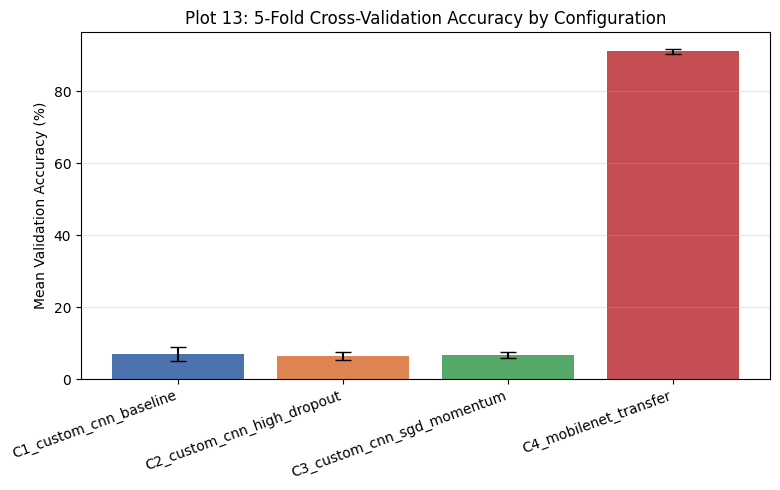


Best configuration selected by CV: C4_mobilenet_transfer
Epoch 1/12
115/115 ━━━━━━━━━━━━━━━━━━━━ 19s 85ms/step - accuracy: 0.7655 - loss: 0.8429
Epoch 2/12
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 84ms/step - accuracy: 0.9245 - loss: 0.2537
Epoch 3/12
115/115 ━━━━━━━━━━━━━━━━━━━━ 9s 81ms/step - accuracy: 0.9549 - loss: 0.1479
Epoch 4/12
115/115 ━━━━━━━━━━━━━━━━━━━━ 9s 75ms/step - accuracy: 0.9698 - loss: 0.0999
Epoch 5/12
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 84ms/step - accuracy: 0.9829 - loss: 0.0668
Epoch 6/12
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 85ms/step - accuracy: 0.9902 - loss: 0.0486
Epoch 7/12
115/115 ━━━━━━━━━━━━━━━━━━━━ 9s 74ms/step - accuracy: 0.9910 - loss: 0.0418
Epoch 8/12
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.9929 - loss: 0.0352
Epoch 9/12
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 84ms/step - accuracy: 0.9948 - loss: 0.0280
Epoch 10/12
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 86ms/step - accuracy: 0.9924 - loss: 0.0279
Epoch 11/12
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 90ms/step - accurac

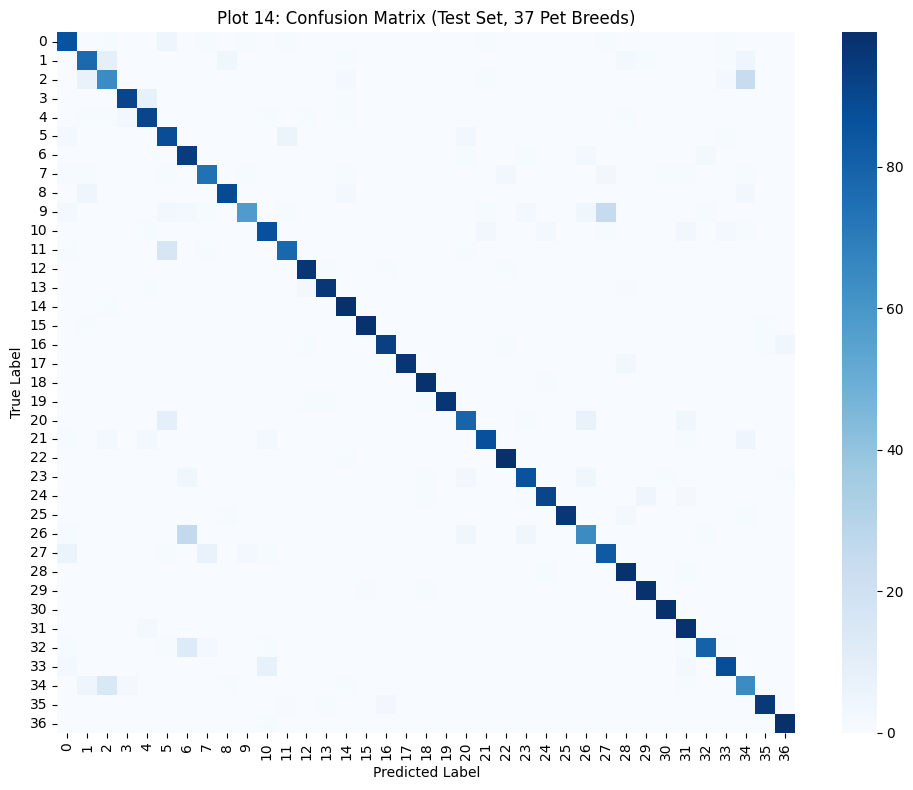

Saved: /content/plots/plot15_misclassified_images.png


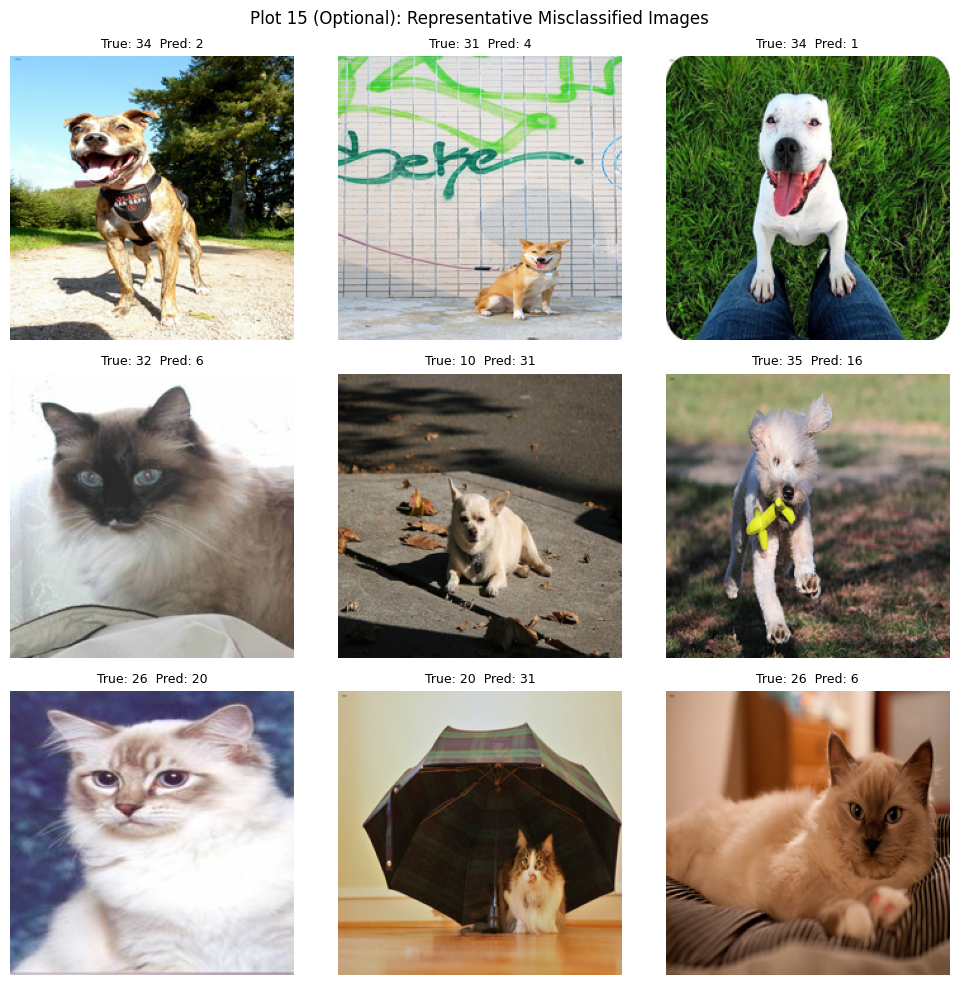


All plots saved to: /content/plots
['plot13_cv_accuracy_by_config.png', 'plot14_confusion_matrix.png', 'plot15_misclassified_images.png']


In [1]:
# =============================================================================
# Experiment 5 -- Plots 13, 14, 15 (5-Fold CV, Confusion Matrix, Misclassified Images)
# Self-contained: run top to bottom in a fresh Colab notebook (GPU runtime).
# =============================================================================

# %% CELL 1: Install / Imports
!pip install -q tensorflow scikit-learn matplotlib seaborn pillow

import os
import gc
import time
import tarfile
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image
from tensorflow.keras import layers, models, regularizers, optimizers, initializers
from tensorflow.keras.applications import MobileNetV2
from sklearn.model_selection import KFold
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

IMG_SIZE = 224
CHANNELS = 3
BATCH_SIZE = 32
NUM_CLASSES = 37

PLOTS_DIR = '/content/plots'
os.makedirs(PLOTS_DIR, exist_ok=True)


def savefig(name):
    path = os.path.join(PLOTS_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches='tight')
    print(f"Saved: {path}")


# %% CELL 2: Download Dataset & Build File/Label Lists (lazy -- no pixels in RAM)
DATA_DIR = '/content/pets'
os.makedirs(DATA_DIR, exist_ok=True)

IMAGES_URL = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz"
ANNOTATIONS_URL = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz"

for url in [IMAGES_URL, ANNOTATIONS_URL]:
    fname = os.path.join(DATA_DIR, os.path.basename(url))
    if not os.path.exists(fname):
        print(f"Downloading {url} ...")
        urllib.request.urlretrieve(url, fname)
    marker = fname + '.extracted'
    if not os.path.exists(marker):
        print(f"Extracting {fname} ...")
        with tarfile.open(fname) as tar:
            try:
                tar.extractall(DATA_DIR, filter='data')
            except TypeError:
                tar.extractall(DATA_DIR)
        open(marker, 'w').close()

IMAGES_DIR = os.path.join(DATA_DIR, 'images')
ANNOT_DIR = os.path.join(DATA_DIR, 'annotations')


def parse_list_file(list_path):
    filepaths, labels = [], []
    with open(list_path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split()
            name, class_id = parts[0], int(parts[1]) - 1
            filepaths.append(os.path.join(IMAGES_DIR, name + '.jpg'))
            labels.append(class_id)
    return filepaths, labels


def filter_valid_files(filepaths, labels):
    valid_fp, valid_lbl = [], []
    for fp, lbl in zip(filepaths, labels):
        try:
            with Image.open(fp) as img:
                img.verify()
            valid_fp.append(fp)
            valid_lbl.append(lbl)
        except Exception as e:
            print(f"Skipping corrupt file {fp}: {e}")
    return valid_fp, valid_lbl


train_files, train_labels_raw = parse_list_file(os.path.join(ANNOT_DIR, 'trainval.txt'))
test_files, test_labels_raw = parse_list_file(os.path.join(ANNOT_DIR, 'test.txt'))
train_files, train_labels_raw = filter_valid_files(train_files, train_labels_raw)
test_files, test_labels_raw = filter_valid_files(test_files, test_labels_raw)

train_files_arr = np.array(train_files)
train_labels_arr = np.array(train_labels_raw, dtype=np.int64)
test_files_arr = np.array(test_files)
test_labels_arr = np.array(test_labels_raw, dtype=np.int64)

print("Train:", len(train_files_arr), "Test:", len(test_files_arr))


# %% CELL 3: tf.data Pipeline (lazy decode from disk -- keeps RAM usage bounded)
def load_and_preprocess(filepath, label):
    image_bytes = tf.io.read_file(filepath)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1.0
    label_oh = tf.one_hot(label, NUM_CLASSES)
    return image, label_oh


def augment(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, 0.15)
    image = tf.image.random_contrast(image, 0.85, 1.15)
    return image, label


def make_tf_dataset(filepaths, labels, training=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(filepaths))
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


def reset_memory():
    tf.keras.backend.clear_session()
    gc.collect()


# %% CELL 4: Model Builders
def build_custom_cnn(weight_init='he_normal', l2_reg=1e-4, dropout_rate=0.4,
                      use_batchnorm=True, num_classes=NUM_CLASSES):
    reg = regularizers.l2(l2_reg) if l2_reg and l2_reg > 0 else None
    init = initializers.get(weight_init) if weight_init != 'zeros' else initializers.Zeros()

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS))
    x = inputs
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding='same',
                           kernel_initializer=init, kernel_regularizer=reg)(x)
        if use_batchnorm:
            x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, kernel_initializer=init, kernel_regularizer=reg)(x)
    if use_batchnorm:
        x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    if dropout_rate and dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(num_classes, activation='softmax',
                            kernel_initializer=init)(x)
    return models.Model(inputs, outputs)


def get_optimizer(name, lr):
    if name == 'sgd':
        return optimizers.SGD(learning_rate=lr)
    elif name == 'momentum':
        return optimizers.SGD(learning_rate=lr, momentum=0.9)
    elif name == 'rmsprop':
        return optimizers.RMSprop(learning_rate=lr)
    elif name == 'adam':
        return optimizers.Adam(learning_rate=lr)
    raise ValueError(f"Unknown optimizer: {name}")


def build_transfer_model(dropout_rate=0.3, fine_tune=False, fine_tune_at=100,
                          num_classes=NUM_CLASSES):
    base_model = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, CHANNELS),
                              include_top=False, weights='imagenet')
    base_model.trainable = fine_tune
    if fine_tune:
        for layer in base_model.layers[:fine_tune_at]:
            layer.trainable = False
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS))
    x = base_model(inputs, training=fine_tune)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inputs, outputs), base_model


# =============================================================================
# %% CELL 5: PLOT 13 -- 5-Fold Cross-Validation Accuracy by Configuration
# =============================================================================
CV_EPOCHS = 4   # bump this up once the pipeline is confirmed to run end-to-end

# Shortlisted configurations (C1-C4). Edit these based on whichever
# weight-init / optimizer / dropout / transfer-learning setting performed
# best in your earlier hyperparameter sweeps (Plots 1-10).
cv_configs = {
    'C1_custom_cnn_baseline': dict(kind='custom', weight_init='he_normal',
                                    l2_reg=1e-4, dropout_rate=0.3,
                                    optimizer='adam', lr=1e-3),
    'C2_custom_cnn_high_dropout': dict(kind='custom', weight_init='he_normal',
                                        l2_reg=1e-4, dropout_rate=0.5,
                                        optimizer='adam', lr=1e-3),
    'C3_custom_cnn_sgd_momentum': dict(kind='custom', weight_init='he_normal',
                                        l2_reg=1e-4, dropout_rate=0.3,
                                        optimizer='momentum', lr=1e-2),
    'C4_mobilenet_transfer': dict(kind='transfer', dropout_rate=0.3),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

for cfg_name, cfg in cv_configs.items():
    print(f"\n===== 5-Fold CV: {cfg_name} =====")
    fold_accs = []
    for fold, (tr_idx, va_idx) in enumerate(kf.split(train_files_arr)):
        print(f"-- Fold {fold+1}/5 --")
        reset_memory()
        f_tr, l_tr = train_files_arr[tr_idx], train_labels_arr[tr_idx]
        f_va, l_va = train_files_arr[va_idx], train_labels_arr[va_idx]
        tr_ds = make_tf_dataset(f_tr, l_tr, training=True)
        va_ds = make_tf_dataset(f_va, l_va, training=False)

        if cfg['kind'] == 'custom':
            model = build_custom_cnn(weight_init=cfg['weight_init'],
                                      l2_reg=cfg['l2_reg'],
                                      dropout_rate=cfg['dropout_rate'])
            model.compile(optimizer=get_optimizer(cfg['optimizer'], cfg['lr']),
                          loss='categorical_crossentropy', metrics=['accuracy'])
        else:
            model, _ = build_transfer_model(dropout_rate=cfg['dropout_rate'], fine_tune=False)
            model.compile(optimizer=optimizers.Adam(1e-3),
                          loss='categorical_crossentropy', metrics=['accuracy'])

        h = model.fit(tr_ds, validation_data=va_ds, epochs=CV_EPOCHS, verbose=0)
        fold_accs.append(max(h.history['val_accuracy']))
        print(f"Fold {fold+1} val accuracy: {fold_accs[-1]:.4f}")

        del model, tr_ds, va_ds
        reset_memory()

    cv_results[cfg_name] = {
        'folds': fold_accs,
        'mean': float(np.mean(fold_accs)),
        'std': float(np.std(fold_accs))
    }

print("\n=== 5-Fold CV Summary ===")
for name, res in cv_results.items():
    print(f"{name}: {res['mean']*100:.2f}% ± {res['std']*100:.2f}%")

plt.figure(figsize=(8, 5))
names = list(cv_results.keys())
means = [cv_results[n]['mean'] * 100 for n in names]
stds = [cv_results[n]['std'] * 100 for n in names]
plt.bar(names, means, yerr=stds, capsize=6, color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'])
plt.ylabel('Mean Validation Accuracy (%)')
plt.title('Plot 13: 5-Fold Cross-Validation Accuracy by Configuration')
plt.xticks(rotation=20, ha='right')
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
savefig('plot13_cv_accuracy_by_config.png')
plt.show()

best_cfg_name = max(cv_results, key=lambda k: cv_results[k]['mean'])
print(f"\nBest configuration selected by CV: {best_cfg_name}")

# =============================================================================
# %% CELL 6: Train Final Model (needed as the source for Plots 14 & 15)
# =============================================================================
FINAL_EPOCHS = 12
reset_memory()
best_cfg = cv_configs[best_cfg_name]
full_train_ds = make_tf_dataset(train_files_arr, train_labels_arr, training=True)
test_ds = make_tf_dataset(test_files_arr, test_labels_arr, training=False)

if best_cfg['kind'] == 'custom':
    final_model = build_custom_cnn(weight_init=best_cfg['weight_init'],
                                    l2_reg=best_cfg['l2_reg'],
                                    dropout_rate=best_cfg['dropout_rate'])
    final_model.compile(optimizer=get_optimizer(best_cfg['optimizer'], best_cfg['lr']),
                         loss='categorical_crossentropy', metrics=['accuracy'])
else:
    final_model, _ = build_transfer_model(dropout_rate=best_cfg['dropout_rate'], fine_tune=False)
    final_model.compile(optimizer=optimizers.Adam(1e-3),
                         loss='categorical_crossentropy', metrics=['accuracy'])

start = time.time()
final_model.fit(full_train_ds, epochs=FINAL_EPOCHS, verbose=1,
                 callbacks=[tf.keras.callbacks.EarlyStopping(
                     monitor='loss', patience=3, restore_best_weights=True)])
final_train_time = time.time() - start

test_loss, test_acc = final_model.evaluate(test_ds, verbose=1)
y_pred_probs = final_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_labels_arr

precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
n_params = final_model.count_params()

print(f"\nTest Accuracy:  {test_acc:.4f}")
print(f"Precision:      {precision:.4f}")
print(f"Recall:         {recall:.4f}")
print(f"F1-score:       {f1:.4f}")
print(f"Training Time:  {final_train_time:.1f}s")
print(f"Parameters:     {n_params:,}")

# =============================================================================
# %% CELL 7: PLOT 14 -- Confusion Matrix
# =============================================================================
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, cmap='Blues', cbar=True)
plt.xlabel('Predicted Label'); plt.ylabel('True Label')
plt.title('Plot 14: Confusion Matrix (Test Set, 37 Pet Breeds)')
plt.tight_layout()
savefig('plot14_confusion_matrix.png')
plt.show()

# =============================================================================
# %% CELL 8: PLOT 15 (Optional) -- Misclassified Images
# =============================================================================
misclassified_idx = np.where(y_pred != y_true)[0]
n_show = min(9, len(misclassified_idx))
sample_idx = np.random.choice(misclassified_idx, n_show, replace=False)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, idx in zip(axes.flat, sample_idx):
    img = Image.open(test_files_arr[idx]).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    ax.imshow(img)
    ax.set_title(f"True: {y_true[idx]}  Pred: {y_pred[idx]}", fontsize=9)
    ax.axis('off')
for ax in axes.flat[n_show:]:
    ax.axis('off')
plt.suptitle('Plot 15 (Optional): Representative Misclassified Images')
plt.tight_layout()
savefig('plot15_misclassified_images.png')
plt.show()

print("\nAll plots saved to:", PLOTS_DIR)
print(sorted(os.listdir(PLOTS_DIR)))

In [ ]:
plot14_confusion_matrix.png